
##  Overview:

###  Objective:

Reproduce and validate the fixed-time synchronization and chaos suppression results for the 4-dimensional hyperchaotic Lü system using a bi-power control law, verifying both theoretical settling-time bounds and initial-state invariance.

###  Key Components Implemented:

1. **Uncontrolled Hyperchaotic Lü System Dynamics**: 4D nonlinear differential equations governing the master and slave systems.
2. **Fixed-Time Bi-Power Control Law**: Combines fast near-origin convergence ($q < 1$) and high-magnitude convergence ($p > 1$) with cancellation of nonlinear terms.
3. **Master-Slave Synchronization**: Simulation of tracking error convergence and empirical settling time calculation against the theoretical Lyapunov upper bound ($T_{\max}$).
4. **Chaos Suppression**: Stabilizing the hyperchaotic system directly to the origin.
5. **Initial-State Invariance Sweep**: Demonstrating that convergence time is independent of the initial error magnitude.

---

##  Mathematical Specifications & Parameters

### 1. Hyperchaotic Lü System Equations

The system is defined by the following 4D autonomous differential equations:


$$\begin{aligned} \dot{x}_1 &= a(x_2 - x_1) + x_4 \\ \dot{x}_2 &= -x_1 x_3 + c x_2 \\ \dot{x}_3 &= x_1 x_2 - b x_3 \\ \dot{x}_4 &= x_1 x_3 + d x_4 \end{aligned}$$

* **System Parameters**: $a = 36.0$, $b = 3.0$, $c = 20.0$, $d = 1.3$

### 2. Fixed-Time Bi-Power Control Law & Parameters

The control input $u$ incorporates a singularity-free signed power function $\text{sig}(z)^\alpha = \text{sign}(z)\vert{}z\vert{}^\alpha$:


$$u = -k_1 \text{sig}(e)^p - k_2 \text{sig}(e)^q - (\dot{x}_{s,\text{nominal}} - \dot{x}_m)$$

* **Gain & Exponent Parameters**:
* $k_1 = 6.0$, $k_2 = 6.0$ (Control gains)
* $p = 1.4$ ($p > 1$, high-magnitude convergence)
* $q = 0.6$ ($0 < q < 1$, near-origin fast convergence)



### 3. Theoretical Settling-Time Bound

The theoretical upper bound for the settling time $T_{\max}$ derived via Lyapunov stability analysis is:


$$T_{\max} = \frac{1}{k_1(p - 1)} + \frac{1}{k_2(1 - q)}$$

* *For the selected parameters*, $T_{\max} \approx \frac{1}{6(0.4)} + \frac{1}{6(0.4)} \approx 0.833 \text{ s}$.

---

##  Code Implementation Summary

| Function / Module | Purpose & Description |
| --- | --- |
| `lu_dynamics(x)` | Computes the 4D state derivatives for the uncontrolled hyperchaotic Lü system. |
| `sig_pow(z, exponent)` | Implements the singularity-free signed power function $\text{sign}(z)\vert{}z\vert{}^\text{exponent}$. |
| `master_slave_ode(t, state)` | Joint ODE system for master ($x_m$) and slave ($x_s$) states, evaluating tracking error $e = x_s - x_m$ and control input $u$. |
| `suppression_ode(t, x)` | Evaluates chaos suppression dynamics driving the system states directly to the origin ($x \to 0$). |
| **Verification & Plotting** | Uses `scipy.integrate.solve_ivp` (`RK45` solver) with high precision tolerances (`rtol=1e-8`, `atol=1e-10`) and generates comparison figures (`week5_suppression_and_sync.png`, `week5_invariance_comparison.png`). |

---

##  Expected Validation Outcomes & Interpretation

* **Error Convergence**: The master-slave error channels $e_i(t)$ ($i=1,2,3,4$) rapidly converge to zero well within the theoretical bound $T_{\max}$.
* **Empirical vs. Theoretical Bounds**: The empirical settling time ($T_s$ at $\Vert{}e\Vert{} < 10^{-3}$) consistently satisfies $T_s \le T_{\max}$, confirming analytical predictions.
* **Initial State Invariance**: Sweeping initial error scaling factors ($\Vert{}e(0)\Vert{} = \text{scale} \times \Vert{}e_0\Vert{}$) demonstrates that convergence duration remains bounded and invariant to initial displacement size—a signature property of fixed-time stability.



Theoretical Lyapunov settling time bound T_max: 0.833 s
Empirical synchronization settling time: 0.453 s (Bound: 0.833 s)


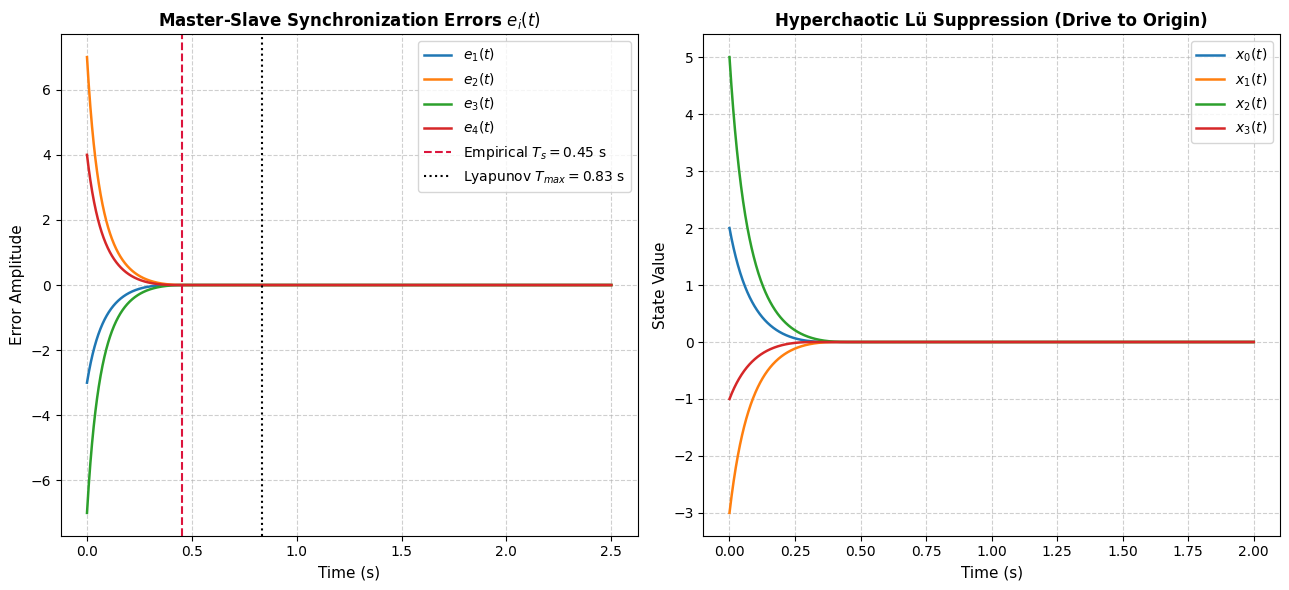

Saved: week5_suppression_and_sync.png


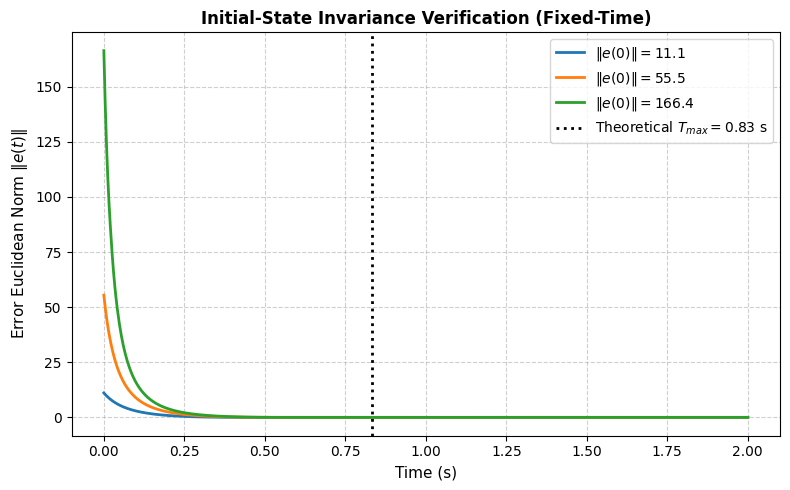

Saved: week5_invariance_comparison.png


In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# 1.Hyperchaotic Lu System Parameters

a = 36.0
b = 3.0
c = 20.0
d = 1.3

def lu_dynamics(x):
    """Uncontrolled 4D hyperchaotic Lü system."""
    x1, x2, x3, x4 = x
    dx1 = a * (x2 - x1) + x4
    dx2 = -x1 * x3 + c * x2
    dx3 = x1 * x2 - b * x3
    dx4 = x1 * x3 + d * x4
    return np.array([dx1, dx2, dx3, dx4])

# 2.Fixed-Time Bi-Power Control Law
k1 = 6.0   # Gain for exponent p > 1
k2 = 6.0   # Gain for exponent q < 1
p = 1.4    # High-magnitude convergence
q = 0.6    # Near-origin fast convergence

def sig_pow(z, exponent):
    """Singularity-free signed power function."""
    return np.sign(z) * (np.abs(z) ** exponent)

# Theoretical Lyapunov upper bound T_max <= 1/(k1*(p-1)) + 1/(k2*(1-q))
T_max = (1.0 / (k1 * (p - 1.0))) + (1.0 / (k2 * (1.0 - q)))
print(f"Theoretical Lyapunov settling time bound T_max: {T_max:.3f} s")

# 3.Simulation: Master-Slave Synchronization

def master_slave_ode(t, state):
    #state: [x1..x4 (master), y1..y4 (slave)]
    xm = state[0:4]
    xs = state[4:8]
    e = xs - xm

    # Uncontrolled master dynamics
    dxm = lu_dynamics(xm)

    #Slave intrinsic dynamics
    dxs_nominal = lu_dynamics(xs)

    # Fixed-time synchronization controller with non-linear cancellation
    # u = -k1*sig(e)^p - k2*sig(e)^q - (f(xs) - f(xm))
    u = -k1 * sig_pow(e, p) - k2 * sig_pow(e, q) - (dxs_nominal - dxm)

    dxs = dxs_nominal + u
    return np.concatenate([dxm, dxs])

# Initial conditions
xm0 = np.array([2.0, -3.0, 5.0, -1.0])
xs0 = np.array([-1.0, 4.0, -2.0, 3.0])
initial_state = np.concatenate([xm0, xs0])
t_span = (0.0, 2.5)
t_eval = np.linspace(0.0, 2.5, 2500)

sol = solve_ivp(master_slave_ode, t_span, initial_state, t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-10)

t = sol.t
e_hist = sol.y[4:8] - sol.y[0:4] # Error channels e1, e2, e3, e4
e_norm = np.linalg.norm(e_hist, axis=0)

# Compute empirical settling time (threshold: ||e|| < 1e-3)
settled_indices = np.where(e_norm < 1e-3)[0]
t_settle_empirical = t[settled_indices[0]] if len(settled_indices) > 0 else None
print(f"Empirical synchronization settling time: {t_settle_empirical:.3f} s (Bound: {T_max:.3f} s)")


# 4.Simulation: Chaos Suppression (Stabilize to Origin)

def suppression_ode(t, x):
    # Target: Drive x -> 0
    dx_nominal = lu_dynamics(x)
    u = -k1 * sig_pow(x, p) - k2 * sig_pow(x, q) - dx_nominal
    return dx_nominal + u

sol_supp = solve_ivp(suppression_ode, (0, 2.0), xm0, t_eval=np.linspace(0, 2.0, 2000), method='RK45')


plt.figure(figsize=(13, 6))

# Panel 1: Master-Slave Error Convergence
plt.subplot(1, 2, 1)
for i in range(4):
    plt.plot(t, e_hist[i], label=f'$e_{i+1}(t)$', lw=1.8)
plt.axvline(t_settle_empirical, color='crimson', linestyle='--', label=f'Empirical $T_s = {t_settle_empirical:.2f}$ s')
plt.axvline(T_max, color='black', linestyle=':', label=f'Lyapunov $T_{{max}} = {T_max:.2f}$ s')
plt.title('Master-Slave Synchronization Errors $e_i(t)$', fontsize=12, fontweight='bold')
plt.xlabel('Time (s)', fontsize=11)
plt.ylabel('Error Amplitude', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

# Panel 2: Chaos Suppression Trajectories
plt.subplot(1, 2, 2)
for i in range(4):
    plt.plot(sol_supp.t, sol_supp.y[i], label=f'$x_{i}(t)$', lw=1.8)
plt.title('Hyperchaotic Lü Suppression (Drive to Origin)', fontsize=12, fontweight='bold')
plt.xlabel('Time (s)', fontsize=11)
plt.ylabel('State Value', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.savefig('week5_suppression_and_sync.png', dpi=300)
plt.show()
plt.close()
print("Saved: week5_suppression_and_sync.png")


# 5.Initial State Invariance Sweep for Slide 2
plt.figure(figsize=(8, 5))
scale_factors = [1.0, 5.0, 15.0]

for scale in scale_factors:
    init_s = np.concatenate([xm0, xm0 + scale * (xs0 - xm0)])
    sol_scale = solve_ivp(master_slave_ode, (0, 2.0), init_s, t_eval=np.linspace(0, 2.0, 1000), method='RK45')
    err = np.linalg.norm(sol_scale.y[4:8] - sol_scale.y[0:4], axis=0)
    plt.plot(sol_scale.t, err, lw=2, label=f'$\\|e(0)\\| = {err[0]:.1f}$')

plt.axvline(T_max, color='black', linestyle=':', lw=2, label=f'Theoretical $T_{{max}} = {T_max:.2f}$ s')
plt.title('Initial-State Invariance Verification (Fixed-Time)', fontsize=12, fontweight='bold')
plt.xlabel('Time (s)', fontsize=11)
plt.ylabel('Error Euclidean Norm $\\|e(t)\\|$', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('week5_invariance_comparison.png', dpi=300)
plt.show()
plt.close()
print("Saved: week5_invariance_comparison.png")